## Random Under Sampling:
We will reduce the majority of the class so that it will have same no of as the minority.

## Random Over Sampling:
We will increase the size of manority is inactive class to the size of majority class i.e. active.

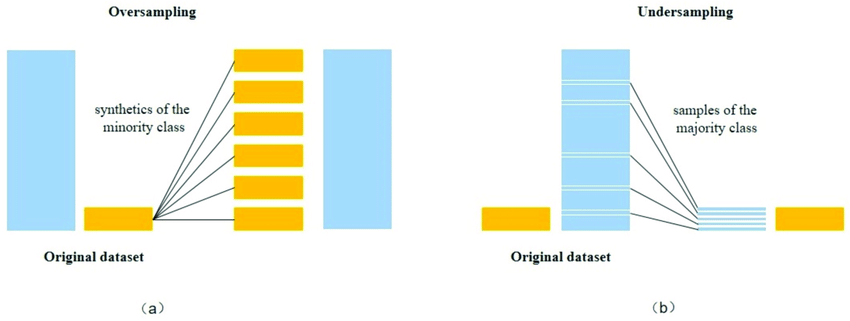

---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

In [2]:
df = pd.read_csv('../datasets/Social_Network_Ads.csv')
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [3]:
df['Purchased'].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [4]:
x = df.iloc[:, :-1]
y = df['Purchased']

x.ndim, y.ndim

(2, 1)

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [6]:
lr = LogisticRegression()
lr.fit(x_train, y_train)

LogisticRegression()

In [7]:
lr.score(x_test, y_test) 

0.8875

In [8]:
lr.predict(x_test)

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0], dtype=int64)

In [9]:
# 19th entry of the dataset is [45,26000,1]
# The output should be 1 but getting 0 as the dataset was imbalanced
lr.predict([[45	,26000]])

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

In [10]:
# 20th entry of the dataset is [46,28000,1]
# The output should be 1 but getting 0 as the dataset was imbalanced
lr.predict([[46	,28000]])

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

The above predicts shows that the model becomes biased as the dataset was imbalanced

---

## Using Sampling

In [11]:
# Under Sampling
from imblearn.under_sampling import RandomUnderSampler

In [12]:
x = df.iloc[:, :-1]
y = df['Purchased']

x.ndim, y.ndim

(2, 1)

In [13]:
ru = RandomUnderSampler()
ru.fit(x,y)

RandomUnderSampler()

In [14]:
ru.fit_resample(x,y)

(     Age  EstimatedSalary
 117   36            52000
 183   33            43000
 180   26            16000
 288   41            79000
 256   41            72000
 ..   ...              ...
 393   60            42000
 395   46            41000
 396   51            23000
 397   50            20000
 399   49            36000
 
 [286 rows x 2 columns],
 117    0
 183    0
 180    0
 288    0
 256    0
       ..
 393    1
 395    1
 396    1
 397    1
 399    1
 Name: Purchased, Length: 286, dtype: int64)

In [15]:
ru_x, ru_y = ru.fit_resample(x,y)

In [16]:
ru_x

,Age,EstimatedSalary
220,41,80000
225,37,53000
317,35,55000
111,37,71000
131,33,31000
...,...,...
393,60,42000
395,46,41000
396,51,23000
397,50,20000


In [17]:
ru_y

220    0
225    0
317    0
111    0
131    0
      ..
393    1
395    1
396    1
397    1
399    1
Name: Purchased, Length: 286, dtype: int64

In [18]:
ru_y.value_counts()

Purchased
0    143
1    143
Name: count, dtype: int64

In [19]:
x_train, x_test, y_train, y_test = train_test_split(ru_x, ru_y, test_size=0.2, random_state=42)

In [20]:
lr1 = LogisticRegression()
lr1.fit(x_train, y_train)

LogisticRegression()

In [21]:
lr1.score(x_test, y_test) 

0.8103448275862069

In [22]:
lr1.predict(x_test)

array([0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0], dtype=int64)

In [23]:
lr1.predict([[45 , 26000]])

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

---

In [24]:
# Over Sampling
from imblearn.over_sampling import RandomOverSampler

In [25]:
x = df.iloc[:, :-1]
y = df['Purchased']

x.ndim, y.ndim

(2, 1)

In [26]:
ro = RandomOverSampler()
ro.fit(x,y)

RandomOverSampler()

In [27]:
ru.fit_resample(x,y)

(     Age  EstimatedSalary
 10    26            80000
 197   20            36000
 332   42            65000
 8     25            33000
 217   40            78000
 ..   ...              ...
 393   60            42000
 395   46            41000
 396   51            23000
 397   50            20000
 399   49            36000
 
 [286 rows x 2 columns],
 10     0
 197    0
 332    0
 8      0
 217    0
       ..
 393    1
 395    1
 396    1
 397    1
 399    1
 Name: Purchased, Length: 286, dtype: int64)

In [28]:
ro_x, ro_y = ru.fit_resample(x,y)

In [29]:
ro_y

54     0
78     0
144    0
349    0
106    0
      ..
393    1
395    1
396    1
397    1
399    1
Name: Purchased, Length: 286, dtype: int64

In [30]:
ru_y.value_counts()

Purchased
0    143
1    143
Name: count, dtype: int64

And further, same steps for model training and further

---